In [1]:
import numpy as np
import pandas as pd

# Fire

In [3]:
fire = pd.read_csv("C:/Users/admin/Desktop/Fire-forest-predection/Data/csv_final/f2/fire_loc.csv")

In [4]:
fire.isna().sum()

longitude    0
latitude     0
dtype: int64

In [67]:
fire.shape

(10985, 2)

# Land cover

In [4]:
land = pd.read_csv("C:/Users/admin/Desktop/Fire-forest-predection/Data/csv_final/f2/grid.csv")
land.isna().sum()

latitude     0
longitude    0
landcover    0
dtype: int64

In [7]:
land.groupby("landcover").size()

landcover
11      1792
14      5846
20     16946
30      7846
50      4079
70     13392
100     3798
110     2539
120     5993
130    16076
140        1
150     7794
180        6
190     2222
200       48
210      820
dtype: int64

# Climat

In [8]:
climat = pd.read_csv("Data/csv_final/f2/climat.csv")
climat.isna().sum()

longitude         0
latitude          0
prec_hiver        6
prec_printemps    6
prec_ete          6
prec_automne      6
tmin_hiver        6
tmin_printemps    6
tmin_ete          6
tmin_automne      6
tmax_hiver        6
tmax_printemps    6
tmax_ete          6
tmax_automne      6
dtype: int64

In [11]:
climat[climat.isna().any(axis=1)]

,longitude,latitude,prec_hiver,prec_printemps,prec_ete,prec_automne,tmin_hiver,tmin_printemps,tmin_ete,tmin_automne,tmax_hiver,tmax_printemps,tmax_ete,tmax_automne
1,-8.952,36.994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26659,-9.502,38.782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41954,-9.167,39.506,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43537,-9.087,39.606,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43673,-9.087,39.615,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51009,-8.917,40.003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
col = ['prec_hiver', 'prec_printemps', 'prec_ete',
       'prec_automne', 'tmin_hiver', 'tmin_printemps', 'tmin_ete',
       'tmin_automne', 'tmax_hiver', 'tmax_printemps', 'tmax_ete',
       'tmax_automne']

In [26]:
from sklearn.neighbors import BallTree

# df avec colonnes: longitude, latitude, value
valid = ~climat[col].isna().any(axis=1)
nan = ~valid

In [ ]:


valid_coords = np.radians(climat.loc[valid, ["longitude", "latitude"]].values)
nan_coords = np.radians(climat.loc[nan, ["longitude", "latitude"]].values)

tree = BallTree(valid_coords, metric="haversine")


dist, idx = tree.query(nan_coords, k=1)

climat.loc[nan,col] = climat.loc[valid,col].values[idx[:, 0]]

In [33]:
climat.loc[nan]

,longitude,latitude,prec_hiver,prec_printemps,prec_ete,prec_automne,tmin_hiver,tmin_printemps,tmin_ete,tmin_automne,tmax_hiver,tmax_printemps,tmax_ete,tmax_automne
1,-8.952,36.994,54.466665,61.241665,3.258333,49.941666,11.500000,12.916667,17.500000,16.166667,19.000000,20.416667,24.833333,22.166667
26659,-9.502,38.782,82.383334,65.624999,9.091667,67.916665,10.333333,12.166667,16.833333,14.916667,16.916667,19.500000,24.583333,21.250000
41954,-9.167,39.506,75.944444,62.188888,9.000000,62.455555,10.333333,12.000000,17.000000,15.000000,17.333333,19.555555,24.111111,21.333333
43537,-9.087,39.606,83.008332,71.141665,10.808333,65.208334,9.333333,11.583333,16.833333,14.500000,16.916667,19.916667,25.083333,21.583333
43673,-9.087,39.615,83.008332,71.141665,10.808333,65.208334,9.333333,11.583333,16.833333,14.500000,16.916667,19.916667,25.083333,21.583333
51009,-8.917,40.003,92.274998,83.516668,14.041667,70.475002,8.333333,11.000000,16.000000,13.666667,17.000000,21.000000,26.750000,22.416667


In [35]:
climat.to_csv("Data/csv_final/f2/climat_filled.csv", index=False)

# Elevation

In [36]:
Elevation = pd.read_csv("Data/csv_final/f2/elevation.csv")
Elevation.isna().sum()

longitude    0
latitude     0
Elevation    0
dtype: int64

# Soil

In [44]:
Soil = pd.read_csv("Data/csv_final/f2/soil.csv")
Soil.isna().sum()

latitude             0
longitude            0
landcover            0
SMU_ID               0
HWSD2_SMU_ID        89
LAYER               89
COARSE              89
SAND                89
SILT                89
CLAY                89
TEXTURE_USDA     54637
TEXTURE_SOTER       89
BULK                89
ORG_CARBON          89
PH_WATER            89
CN_RATIO            89
CEC_SOIL            89
CEC_CLAY            89
CEC_EFF             89
BSAT                89
ALUM_SAT            89
ESP                 89
TCARBON_EQ          89
GYPSUM              89
ELEC_COND           89
dtype: int64

In [45]:
Soil.shape

(608947, 25)

In [46]:
col = ['HWSD2_SMU_ID', 'LAYER',
       'COARSE', 'SAND', 'SILT', 'CLAY', 'TEXTURE_SOTER',
       'BULK', 'ORG_CARBON', 'PH_WATER', 'CN_RATIO', 'CEC_SOIL', 'CEC_CLAY',
       'CEC_EFF', 'BSAT', 'ALUM_SAT', 'ESP', 'TCARBON_EQ', 'GYPSUM',
       'ELEC_COND']

seul ="TEXTURE_USDA"

In [47]:
valid = ~Soil[col].isna().all(axis=1)
nan = ~valid

In [ ]:


valid_coords = np.radians(Soil.loc[valid, ["longitude", "latitude"]].values)
nan_coords = np.radians(Soil.loc[nan, ["longitude", "latitude"]].values)

tree = BallTree(valid_coords, metric="haversine")


dist, idx = tree.query(nan_coords, k=1)


Soil.loc[nan,col] = Soil.loc[valid,col].values[idx[:, 0]]

In [56]:
Soil.isna().sum()

latitude             0
longitude            0
landcover            0
SMU_ID               0
HWSD2_SMU_ID         0
LAYER                0
COARSE               0
SAND                 0
SILT                 0
CLAY                 0
TEXTURE_USDA     54637
TEXTURE_SOTER        0
BULK                 0
ORG_CARBON           0
PH_WATER             0
CN_RATIO             0
CEC_SOIL             0
CEC_CLAY             0
CEC_EFF              0
BSAT                 0
ALUM_SAT             0
ESP                  0
TCARBON_EQ           0
GYPSUM               0
ELEC_COND            0
dtype: int64

In [57]:
Soil.shape

(608947, 25)

In [53]:
valid = ~Soil[seul].isna()
nan = ~valid

In [58]:

# coordonnees en radians longitude	latitude
valid_coords = np.radians(Soil.loc[valid, ["longitude", "latitude"]].values)
nan_coords = np.radians(Soil.loc[nan, ["longitude", "latitude"]].values)

# arbre
tree = BallTree(valid_coords, metric="haversine")

# indice du plus proche voisin
dist, idx = tree.query(nan_coords, k=1)

# remplacer par la valeur la plus proche
Soil.loc[nan,seul] = Soil.loc[valid,seul].values[idx[:, 0]]

In [59]:
Soil.isna().sum()

latitude         0
longitude        0
landcover        0
SMU_ID           0
HWSD2_SMU_ID     0
LAYER            0
COARSE           0
SAND             0
SILT             0
CLAY             0
TEXTURE_USDA     0
TEXTURE_SOTER    0
BULK             0
ORG_CARBON       0
PH_WATER         0
CN_RATIO         0
CEC_SOIL         0
CEC_CLAY         0
CEC_EFF          0
BSAT             0
ALUM_SAT         0
ESP              0
TCARBON_EQ       0
GYPSUM           0
ELEC_COND        0
dtype: int64

In [60]:
Soil.to_csv("Data/csv_final/f2/soil_filled.csv", index=False)

In [6]:
from sklearn.neighbors import BallTree
# fichiers
all_points = pd.read_csv("C:/Users/admin/Desktop/Fire-forest-predection/Data/csv_final/f2/grid.csv")      # tous les points
fire_points = pd.read_csv("C:/Users/admin/Desktop/Fire-forest-predection/Data/csv_final/f2/fire_loc.csv") # points feu

# coords en radians (BallTree haversine attend lat, lon)
all_rad = np.radians(all_points[["latitude", "longitude"]].values)
fire_rad = np.radians(fire_points[["latitude", "longitude"]].values)

# arbre des points feu
tree = BallTree(fire_rad, metric="haversine")

# distance du plus proche voisin pour chaque point du grid
dist, idx = tree.query(all_rad, k=1)

# seuil en km
seuil_km = 1.0
seuil_rad = seuil_km / 6371.0  # rayon Terre en km

# colonne in_fire
all_points["in_fire"] = (dist[:, 0] <= seuil_rad).astype(int)

# optionnel: distance en km
all_points["dist_fire_km"] = dist[:, 0] * 6371.0

all_points["in_fire"].value_counts()

in_fire
0    84596
1     4602
Name: count, dtype: int64

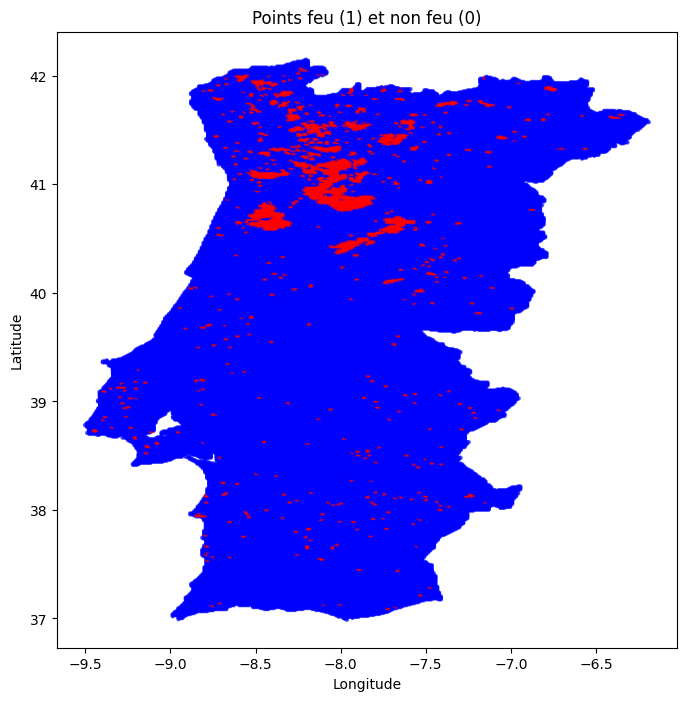

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
colors = all_points["in_fire"].map({0: "blue", 1: "red"})
plt.scatter(all_points["longitude"], all_points["latitude"], c=colors, s=5, alpha=0.6)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Points feu (1) et non feu (0)")
plt.show()

In [9]:
all_points.to_csv("C:/Users/admin/Desktop/Fire-forest-predection/Data/csv_final/f2/grid_with_fire2.csv", index=False)

In [ ]:
import numpy as np
from sklearn.neighbors import BallTree


seuil_km = 1.0
seuil_rad = seuil_km / 6371.0 


all_rad = np.radians(all_points[["latitude", "longitude"]].values)
climat_rad = np.radians(climat[["latitude", "longitude"]].values)


tree = BallTree(climat_rad, metric="haversine")


dist, idx = tree.query(all_rad, k=1)


dist_km = dist[:, 0] * 6371.0


climat_cols = climat.columns.difference(["longitude", "latitude"])
merged = all_points.copy()
merged[climat_cols] = climat.iloc[idx[:, 0]][climat_cols].values


merged["dist_climat_km"] = dist_km
merged["match_climat"] = (dist[:, 0] <= seuil_rad).astype(int)


print("Total all_points:", len(all_points))
print("Match <= seuil:", merged["match_climat"].sum())
print("No match:", (merged["match_climat"] == 0).sum())
print("Distance min/max (km):", merged["dist_climat_km"].min(), merged["dist_climat_km"].max())


merged.loc[merged["match_climat"] == 0, climat_cols] = np.nan

Total all_points: 89198
Match <= seuil: 89198
No match: 0
Distance min/max (km): 0.0003512594419692697 0.07052210857647025


In [90]:
merged.drop(columns=["lat_r", "lon_r"], inplace=True)

In [91]:
merged.isna().sum()

latitude          0
longitude         0
landcover         0
in_fire           0
dist_fire_km      0
prec_automne      0
prec_ete          0
prec_hiver        0
prec_printemps    0
tmax_automne      0
tmax_ete          0
tmax_hiver        0
tmax_printemps    0
tmin_automne      0
tmin_ete          0
tmin_hiver        0
tmin_printemps    0
dist_climat_km    0
match_climat      0
dtype: int64

In [ ]:

seuil_km = 1.0
seuil_rad = seuil_km / 6371.0


all_rad = np.radians(merged[["latitude", "longitude"]].values)
elev_rad = np.radians(Elevation[["latitude", "longitude"]].values)


tree = BallTree(elev_rad, metric="haversine")


dist, idx = tree.query(all_rad, k=1)


dist_km = dist[:, 0] * 6371.0


elev_cols = Elevation.columns.difference(["longitude", "latitude"])
merged_elev = merged.copy()
merged_elev[elev_cols] = Elevation.iloc[idx[:, 0]][elev_cols].values


merged_elev["dist_elev_km"] = dist_km
merged_elev["match_elev"] = (dist[:, 0] <= seuil_rad).astype(int)


print("Total all_points:", len(merged))
print("Match <= seuil:", merged_elev["match_elev"].sum())
print("No match:", (merged_elev["match_elev"] == 0).sum())
print("Distance min/max (km):", merged_elev["dist_elev_km"].min(), merged_elev["dist_elev_km"].max())
 
h
merged_elev.loc[merged_elev["match_elev"] == 0, elev_cols] = np.nan

Total all_points: 89198
Match <= seuil: 89198
No match: 0
Distance min/max (km): 0.0 0.0


In [ ]:



seuil_km = 1.0
seuil_rad = seuil_km / 6371.0


all_rad = np.radians(merged_elev[["latitude", "longitude"]].values)
soil_rad = np.radians(Soil[["latitude", "longitude"]].values)


tree = BallTree(soil_rad, metric="haversine")


dist, idx = tree.query(all_rad, k=1)


dist_km = dist[:, 0] * 6371.0


soil_cols = Soil.columns.difference(["longitude", "latitude"])
merged_soil = merged_elev.copy()
merged_soil[soil_cols] = Soil.iloc[idx[:, 0]][soil_cols].values


merged_soil["dist_soil_km"] = dist_km
merged_soil["match_soil"] = (dist[:, 0] <= seuil_rad).astype(int)


print("Total points:", len(merged_elev))
print("Match <= seuil:", merged_soil["match_soil"].sum())
print("No match:", (merged_soil["match_soil"] == 0).sum())
print("Distance min/max (km):", merged_soil["dist_soil_km"].min(), merged_soil["dist_soil_km"].max())

merged_soil.loc[merged_soil["match_soil"] == 0, soil_cols] = np.nan

Total points: 89198
Match <= seuil: 89198
No match: 0
Distance min/max (km): 0.0 0.0
